<p style="text-align: center; font-family: 'Courier New', Courier, monospace; font-size: 30px; font-weight: bold; color: blue;">
LoRaWAN Indoor Dataset: Robustness Checks
</p>

This notebook checks whether the ranging results of `03_Path_Loss_Modeling.ipynb` and `04_Distance_Estimation.ipynb` hold beyond the six links they were fitted on. Everything is rebuilt from the cleaned dataset with the split of `01_Data Preparation.ipynb`, the Kalman filter of `02_Kalman_Filtering.ipynb` and the models of `03` (without SNR). Section 0 confirms that this reproduces the saved results of `04`.

0. Rebuild the pipeline and check it against `04`.
1. Leave-one-link-out ranging: fit on five links, range the sixth.
2. Per-link calibration: offset of the new link from its last N packets.
3. Removal of the SF and channel shifts in the measured path loss.
4. Day-block bootstrap intervals.
5. Baselines: causal smoothing, a Kalman filter with tuned Q, a constant guess and LightGBM rangers.
6. Censoring: are weak packets missing from the log?

### 0. Rebuild the pipeline and check it against `04`

In [1]:
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy.optimize import curve_fit

sns.set_style("darkgrid")
sns.set_context("talk", font_scale=0.9)

In [2]:
# load, sort by time, chronological 80/20 split (as in 01)
DATA_PATH = '../all_data_files/cleaned_dataset_per_device.csv'
ENV = ['co2', 'humidity', 'pm25', 'pressure', 'temperature']
LINKS = ['ED0', 'ED1', 'ED2', 'ED3', 'ED4', 'ED5']
MODELS = ['MWM', 'MWM-KF', 'MWM-EP', 'MWM-EP-KF']
OFFSET = 17.26  # TX power (14 dBm) - cable loss + antenna gains, as in 02

df = pd.read_csv(DATA_PATH, parse_dates=['time'],
                 usecols=['time', 'device_id', 'rssi', 'tx_power', 'snr', 'SF', 'f_count', 'frequency', 'distance',
                          'c_walls', 'w_walls', 'exp_pl'] + ENV)
df = df.sort_values('time').reset_index(drop=True)
df['rssi'] = df.rssi + 14 - df.tx_power  # RSSI at 14 dBm, as in 02 (TTN's ADR set the power of each uplink)

split_idx = int(len(df) * 0.8)
df['train'] = df.index < split_idx
df['day'] = (df.time.dt.floor('D') - df.time.dt.floor('D').min()).dt.days
true_distance = df.groupby('device_id').distance.first()

print(f"Training samples: {split_idx}, Test samples: {len(df) - split_idx}")
print(f"Test window: {df.time[split_idx]} -> {df.time.iloc[-1]}")

Training samples: 2128219, Test samples: 532055
Test window: 2025-07-21 21:22:03.897840+00:00 -> 2025-09-30 23:59:55.971870+00:00


In [3]:
# Kalman filter of 02 (R0 = 0.22, innovation-driven R clipped to [0.12, 0.38]); only Q is varied in section 5
def kalman(z, Q=0.003):
    R, P, x = 0.22, 0.22, z[0]
    out = np.empty(len(z))
    out[0] = x
    for k in range(1, len(z)):
        P_pred = P + Q
        S = P_pred + R
        gain = P_pred / S
        innov = z[k] - x
        x = x + gain * innov
        P = (1 - gain) * P_pred
        alpha = min(max(innov ** 2 / S, 0.95), 1.05)
        R = min(max(0.99 * R + 0.01 * alpha * R, 0.12), 0.38)
        out[k] = x
    return out


# causal smoothing of the RSSI per device, training and test part separately (as in 02)
def smooth(rssi, method, window=None, Q=0.003):
    out = np.empty(len(df))
    for idx in df.groupby(['device_id', 'train']).indices.values():
        s = pd.Series(rssi[idx])
        if method == 'kalman':
            out[idx] = kalman(s.to_numpy(), Q)
        elif method == 'mean':
            out[idx] = s.rolling(window, min_periods=1).mean()
        elif method == 'median':
            out[idx] = s.rolling(window, min_periods=1).median()
        else:
            out[idx] = s.ewm(span=window).mean()
    return out


plr = df.exp_pl.to_numpy()                              # measured path loss
plf = OFFSET - smooth(df.rssi.to_numpy(), 'kalman')     # Kalman-filtered path loss

In [4]:
# path loss models of 03 (EP without SNR) and their inversion as in 04
def mw(x, PL_d0, n, L_c, L_w):
    d, c_walls, w_walls = x
    return PL_d0 + 10 * n * np.log10(d) + c_walls * L_c + w_walls * L_w


def ep(x, PL_d0, n, L_c, L_w, a_co2, a_hum, a_pm25, a_pres, a_temp):
    d, freq, c_walls, w_walls, co2, hum, pm25, pres, temp = x
    return (PL_d0 + 10 * n * np.log10(d) + 20 * np.log10(freq) + c_walls * L_c + w_walls * L_w
            + a_co2 * co2 + a_hum * hum + a_pm25 * pm25 + a_pres * pres + a_temp * temp)


def inputs(h, with_env):
    cols = ['distance', 'frequency', 'c_walls', 'w_walls'] + ENV if with_env else ['distance', 'c_walls', 'w_walls']
    return h[cols].to_numpy().T


def fit(a, target, with_env, step=1):
    f, p0 = (ep, [30, 2, 5, 3] + [0.01] * 5) if with_env else (mw, [30, 2, 5, 3])
    a = a.iloc[::step]
    return curve_fit(f, inputs(a, with_env), a[target].to_numpy(), p0=p0, maxfev=100000)[0]


def path_loss(p, h, with_env):
    return (ep if with_env else mw)(inputs(h, with_env), *p)


def invert(p, h, PL, with_env):
    n, L_c, L_w = p[1:4]
    walls = h.c_walls.to_numpy() * L_c + h.w_walls.to_numpy() * L_w
    if with_env:
        env = sum(p[4 + i] * h[c].to_numpy() for i, c in enumerate(ENV))
        return 10 ** ((PL - p[0] - 20 * np.log10(h.frequency.to_numpy()) - walls - env) / (10 * n))
    return 10 ** ((PL - p[0] - walls) / (10 * n))

In [5]:
CAL = [0, 1, 10, 60, 1440, 10080]  # packets of the new link used for calibration: none, 1, 10, ~1 hour, ~1 day, ~1 week


# one fit with all links (hold = None) or without the link `hold`; returns the absolute ranging errors of the test packets
def run_job(job):
    model, hold = job
    with_env, target = 'EP' in model, ('plf' if model.endswith('KF') else 'plr')
    train = df[df.train]
    p = fit(train if hold is None else train[train.device_id != hold], target, with_env)
    errors = {}
    for link in ([hold] if hold else LINKS):
        test = df[~df.train & (df.device_id == link)]
        past = train[train.device_id == link]
        for N in (CAL if hold else [0]):
            # offset of the new link from its last N training packets, whose distance is known
            offset = 0.0 if N == 0 else np.median(past[target].to_numpy()[-N:] - path_loss(p, past.iloc[-N:], with_env))
            est = invert(p, test, test[target].to_numpy() - offset, with_env)
            errors[(link, N)] = np.abs(est - test.distance.to_numpy()).astype(np.float32)
    return model, hold, errors


# ranging errors with every link in the fit ('fit') and with each link left out ('lolo');
# the workers are forked after the path-loss columns are set
def evaluate(plr, plf, models=MODELS):
    df['plr'], df['plf'] = plr, plf
    res = {}
    with mp.get_context('fork').Pool(len(LINKS)) as pool:
        for model, hold, errors in pool.imap_unordered(run_job, [(m, h) for m in models for h in [None] + LINKS]):
            for (link, N), e in errors.items():
                res[('fit' if hold is None else 'lolo', model, link, N)] = e
    return res


def mae_by_link(res, scope, N=0, models=MODELS):
    t = pd.DataFrame({m: {l: res[(scope, m, l, N)].mean() for l in LINKS} for m in models})
    t.loc['mean over links'] = t.mean()
    return t


def pooled(res, scope, model, N=0):
    # MAE and RMSE over all test packets of the six links
    e = np.concatenate([res[(scope, model, l, N)] for l in LINKS]).astype(float)
    return e.mean(), np.sqrt((e ** 2).mean())

In [6]:
res = evaluate(plr, plf)

# the rebuilt pipeline must reproduce the saved results of 04
saved = pd.read_csv('Data Files/distance_metrics.csv', index_col=0)
check = pd.DataFrame({'MAE rebuilt': [pooled(res, 'fit', m)[0] for m in MODELS], 'MAE 04': saved.loc['MAE'].to_numpy(),
                      'RMSE rebuilt': [pooled(res, 'fit', m)[1] for m in MODELS], 'RMSE 04': saved.loc['RMSE'].to_numpy()},
                     index=MODELS)
display(check.round(3))
assert np.allclose(check['MAE rebuilt'], check['MAE 04'], atol=1e-3) and np.allclose(check['RMSE rebuilt'], check['RMSE 04'], atol=1e-3), \
    'does not reproduce 04: run 01-04 on the same dataset first'

,MAE rebuilt,MAE 04,RMSE rebuilt,RMSE 04
MWM,4.214,4.214,6.260,6.260
MWM-KF,3.728,3.728,5.346,5.346
MWM-EP,4.204,4.204,6.400,6.400
MWM-EP-KF,3.699,3.699,5.404,5.404


### 1. Leave-one-link-out ranging

Each link is left out in turn: the models are fitted on the training period of the other five links and invert the test period of the sixth. The same models with all six links in the fit (as in `04`) are shown for comparison.

In [7]:
print('MAE (m) per link')
display(pd.concat({'link left out': mae_by_link(res, 'lolo'), 'link in the fit': mae_by_link(res, 'fit')}).round(2))

print('Over all test packets of the six links (m)')
display(pd.DataFrame({(scope, stat): [pooled(res, scope, m)[i] for m in MODELS]
                      for scope in ('fit', 'lolo') for i, stat in enumerate(('MAE', 'RMSE'))}, index=MODELS).round(2))

MAE (m) per link


MWM  MWM-KF  MWM-EP  MWM-EP-KF
link left out   ED0               1.61    1.43    1.67       1.48
                ED1               1.95    1.86    1.90       1.80
                ED2               4.75    4.13    5.17       4.49
                ED3               6.47    6.53    6.09       6.13
                ED4              12.99   12.70   14.18      13.89
                ED5              15.63   14.34   16.99      15.82
                mean over links   7.23    6.83    7.67       7.27
link in the fit ED0               1.72    1.47    1.91       1.64
                ED1               1.42    1.22    1.55       1.36
                ED2               4.26    3.75    4.33       3.76
                ED3               5.04    5.07    4.54       4.53
                ED4               5.65    4.36    6.14       4.98
                ED5               7.20    6.51    6.75       5.93
                mean over links   4.21    3.73    4.20       3.70

Over all test packets of the six links (m)


fit        lolo       
            MAE  RMSE   MAE   RMSE
MWM        4.21  6.26  7.24  11.34
MWM-KF     3.73  5.35  6.84  10.19
MWM-EP     4.20  6.40  7.68  12.15
MWM-EP-KF  3.70  5.40  7.28  11.01

### 2. Per-link calibration

The new link gets one offset: the median difference between its measured path loss and the fitted model, taken over its last N packets before the test period, whose distance is known. The offset is subtracted before the inversion.

In [8]:
print('MAE (m), mean over the six left-out links, by calibration window (packets)')
display(pd.DataFrame({m: {N: mae_by_link(res, 'lolo', N, [m]).loc['mean over links', m] for N in CAL} for m in MODELS}).round(2))

print('RMSE (m) over all test packets')
display(pd.DataFrame({m: {N: pooled(res, 'lolo', m, N)[1] for N in CAL} for m in MODELS}).round(2))

print('MWM-KF, MAE (m) per left-out link by calibration window')
display(pd.DataFrame({N: mae_by_link(res, 'lolo', N, ['MWM-KF'])['MWM-KF'] for N in CAL}).round(2))

MAE (m), mean over the six left-out links, by calibration window (packets)


,MWM,MWM-KF,MWM-EP,MWM-EP-KF
0,7.23,6.83,7.67,7.27
1,6.42,5.19,6.19,4.95
10,6.11,5.02,5.89,4.79
60,5.52,4.79,5.33,4.58
1440,4.89,4.51,4.82,4.37
10080,4.33,3.90,4.46,3.93


RMSE (m) over all test packets


,MWM,MWM-KF,MWM-EP,MWM-EP-KF
0,11.34,10.19,12.15,11.01
1,9.55,7.90,9.21,7.54
10,9.43,7.84,9.06,7.47
60,8.89,7.52,8.52,7.17
1440,7.75,7.04,7.57,6.76
10080,6.80,5.92,6.94,5.96


MWM-KF, MAE (m) per left-out link by calibration window


,0,1,10,60,1440,10080
ED0,1.43,1.41,1.41,1.41,1.50,1.52
ED1,1.86,2.72,2.61,2.63,2.08,2.09
ED2,4.13,9.30,9.30,8.74,9.07,5.96
ED3,6.53,3.09,2.29,2.27,2.36,2.08
ED4,12.70,5.10,4.87,4.34,4.02,3.70
ED5,14.34,9.55,9.63,9.36,8.01,8.06
mean over links,6.83,5.19,5.02,4.79,4.51,3.90


### 3. SF and channel shifts

The measured path loss shifts with the spreading factor and the channel, identically on all links. The shifts are estimated from the training period (link levels removed), taken out of the RSSI before filtering and inversion, and the evaluation of sections 1 and 2 is repeated.

In [9]:
# least squares on link, SF and channel levels (every 5th training row); shifts relative to the first level
a = df[df.train].iloc[::5]
levels = {c: sorted(a[c].unique()) for c in ['device_id', 'SF', 'frequency']}
names = [(c, l) for c in levels for l in levels[c][1:]]
X = np.column_stack([np.ones(len(a))] + [(a[c] == l).to_numpy(float) for c, l in names])
effect = dict(zip(names, np.linalg.lstsq(X, a.exp_pl.to_numpy(), rcond=None)[0][1:]))
sf_shift = {l: effect.get(('SF', l), 0.0) for l in levels['SF']}
channel_shift = {l: effect.get(('frequency', l), 0.0) for l in levels['frequency']}
display(pd.DataFrame({'shift (dB)': sf_shift}).rename_axis('SF').round(2).T)
display(pd.DataFrame({'shift (dB)': channel_shift}).rename_axis('channel (MHz)').round(2).T)

rssi_adj = df.rssi.to_numpy() + df.SF.map(sf_shift).to_numpy() + df.frequency.map(channel_shift).to_numpy()
res_adj = evaluate(OFFSET - rssi_adj, OFFSET - smooth(rssi_adj, 'kalman'))

SF,7,8,9,10,11,12
shift (dB),0.0,-0.4,1.87,-1.6,-0.83,0.7


channel (MHz),867.1,867.3,867.5,867.7,867.9,868.1,868.3,868.5
shift (dB),0.0,-1.23,-1.76,-1.32,-0.26,-0.54,-1.84,-2.3


In [10]:
print('MAE (m), mean over links')
display(pd.DataFrame({(scope, variant): mae_by_link(r, scope).loc['mean over links']
                      for scope in ('fit', 'lolo') for variant, r in (('as is', res), ('SF and channel removed', res_adj))}).T.round(2))

print('SF and channel removed, MAE (m), mean over the six left-out links, by calibration window (packets)')
display(pd.DataFrame({m: {N: mae_by_link(res_adj, 'lolo', N, [m]).loc['mean over links', m] for N in CAL} for m in MODELS}).round(2))

MAE (m), mean over links


MWM  MWM-KF  MWM-EP  MWM-EP-KF
fit  as is                   4.21    3.73    4.20       3.70
     SF and channel removed  3.99    3.72    3.97       3.69
lolo as is                   7.23    6.83    7.67       7.27
     SF and channel removed  7.03    6.80    7.46       7.24

SF and channel removed, MAE (m), mean over the six left-out links, by calibration window (packets)


,MWM,MWM-KF,MWM-EP,MWM-EP-KF
0,7.03,6.80,7.46,7.24
1,5.28,4.90,5.08,4.68
10,5.29,4.89,5.09,4.67
60,5.08,4.75,4.88,4.55
1440,4.75,4.49,4.59,4.36
10080,4.19,3.89,4.22,3.94


### 4. Day-block bootstrap

The test days are resampled with replacement (2000 times, all links together), which keeps the correlation between neighbouring packets. The intervals do not cover the uncertainty from having only six links.

In [11]:
test_days = np.sort(df.day[~df.train].unique())
draw = np.random.default_rng(0).integers(0, len(test_days), (2000, len(test_days)))


# summed absolute error and packet count per test day (rows) and link (columns)
def day_totals(res, scope, model, N=0):
    S, C = np.zeros((len(test_days), len(LINKS))), np.zeros((len(test_days), len(LINKS)))
    for j, link in enumerate(LINKS):
        d = np.searchsorted(test_days, df.day[~df.train & (df.device_id == link)].to_numpy())
        S[:, j] = np.bincount(d, weights=res[(scope, model, link, N)], minlength=len(test_days))
        C[:, j] = np.bincount(d, minlength=len(test_days))
    return S, C


def boot(S, C):
    # pooled MAE of every resample of the test days
    return S.sum(1)[draw].sum(1) / C.sum(1)[draw].sum(1)


def interval(x):
    return f'{np.percentile(x, 2.5):.2f} to {np.percentile(x, 97.5):.2f}'


for scope, title in (('fit', 'link in the fit'), ('lolo', 'link left out')):
    tot = {m: day_totals(res, scope, m) for m in MODELS}
    print(f'Pooled MAE (m), {title}')
    display(pd.DataFrame({m: {'MAE': tot[m][0].sum() / tot[m][1].sum(), '95 % interval': interval(boot(*tot[m]))} for m in MODELS}).T)
    print(f'Paired differences in pooled MAE (m), {title}')
    rows = {}
    for a_, b_, label in (('MWM-KF', 'MWM', 'Kalman filter (MWM-KF - MWM)'), ('MWM-EP', 'MWM', 'environment, raw (MWM-EP - MWM)'),
                          ('MWM-EP-KF', 'MWM-KF', 'environment, filtered (MWM-EP-KF - MWM-KF)'), ('MWM-EP-KF', 'MWM', 'full pipeline (MWM-EP-KF - MWM)')):
        d = boot(*tot[a_]) - boot(*tot[b_])
        rows[label] = {'difference': tot[a_][0].sum() / tot[a_][1].sum() - tot[b_][0].sum() / tot[b_][1].sum(),
                       '95 % interval': interval(d), 'zero inside': bool(np.percentile(d, 2.5) < 0 < np.percentile(d, 97.5))}
    display(pd.DataFrame(rows).T)

S, C = day_totals(res, 'lolo', 'MWM-KF')
print('MWM-KF, link left out, MAE (m) per link')
display(pd.DataFrame({l: {'MAE': S[:, j].sum() / C[:, j].sum(), '95 % interval': interval(S[:, j][draw].sum(1) / C[:, j][draw].sum(1))}
                      for j, l in enumerate(LINKS)}).T)

print('MWM-KF, link left out, pooled MAE (m) by calibration window (packets)')
display(pd.DataFrame({N: {'MAE': day_totals(res, 'lolo', 'MWM-KF', N)[0].sum() / day_totals(res, 'lolo', 'MWM-KF', N)[1].sum(),
                          '95 % interval': interval(boot(*day_totals(res, 'lolo', 'MWM-KF', N)))} for N in CAL}).T)

Pooled MAE (m), link in the fit


,MAE,95 % interval
MWM,4.214112,4.00 to 4.45
MWM-KF,3.728209,3.50 to 3.98
MWM-EP,4.204219,3.95 to 4.48
MWM-EP-KF,3.698855,3.43 to 3.99


Paired differences in pooled MAE (m), link in the fit


,difference,95 % interval,zero inside
Kalman filter (MWM-KF - MWM),-0.485902,-0.52 to -0.45,False
"environment, raw (MWM-EP - MWM)",-0.009892,-0.09 to 0.08,True
"environment, filtered (MWM-EP-KF - MWM-KF)",-0.029354,-0.12 to 0.07,True
full pipeline (MWM-EP-KF - MWM),-0.515257,-0.60 to -0.42,False


Pooled MAE (m), link left out


...

,difference,95 % interval,zero inside
Kalman filter (MWM-KF - MWM),-0.405045,-0.44 to -0.37,False
"environment, raw (MWM-EP - MWM)",0.436073,0.31 to 0.57,False
"environment, filtered (MWM-EP-KF - MWM-KF)",0.440111,0.31 to 0.58,False
full pipeline (MWM-EP-KF - MWM),0.035066,-0.11 to 0.19,True


MWM-KF, link left out, MAE (m) per link


,MAE,95 % interval
ED0,1.429707,1.22 to 1.66
ED1,1.859931,1.54 to 2.23
ED2,4.126421,3.57 to 4.70
ED3,6.526708,6.23 to 6.81
ED4,12.70118,11.23 to 14.18
ED5,14.339664,12.41 to 16.41


MWM-KF, link left out, pooled MAE (m) by calibration window (packets)


,MAE,95 % interval
0,6.835287,6.35 to 7.34
1,5.206305,4.72 to 5.69
10,5.034312,4.56 to 5.51
60,4.804699,4.35 to 5.26
1440,4.518612,4.10 to 4.93
10080,3.910141,3.62 to 4.21


### 5. Baselines

**Smoothing.** The structure-only model is fitted on RSSI smoothed by a causal moving average, a causal moving median, an exponential average, or the Kalman filter with a tuned Q. Window or Q is chosen on the last 20 % of the training period (fit on the first 80 %), never on the test period. As in `02`, the test part starts a new filter, which penalises long windows. A window longer than any stream is the average of everything so far.

In [12]:
train = df[df.train]
cut = int(len(train) * 0.8)
rssi = df.rssi.to_numpy()


# structure-only model fitted on the first 80 % of the training period, MAE on the last 20 %
def validation_mae(plf_candidate):
    t = train.assign(plf=plf_candidate[:split_idx])  # the training rows come first
    p = fit(t.iloc[:cut], 'plf', False, step=5)
    v = t.iloc[cut:]
    return np.abs(invert(p, v, v.plf.to_numpy(), False) - v.distance.to_numpy()).mean()


# packets, one per minute; 400000 is longer than any stream, i.e. the average of everything so far
windows = [5, 10, 20, 30, 60, 120, 300, 600, 1440, 2880, 5760, 10080, 20160, 43200, 86400, 172800, 400000]
Qs = [10.0 ** e for e in range(-12, 0)] + [0.003]
validation = {method: {w: validation_mae(OFFSET - smooth(rssi, method, window=w)) for w in windows} for method in ('mean', 'median', 'ewm')}
validation['kalman'] = {q: validation_mae(OFFSET - smooth(rssi, 'kalman', Q=q)) for q in Qs}
raw_validation = validation_mae(OFFSET - rssi)
chosen = {method: min(v, key=v.get) for method, v in validation.items()}

print('Validation MAE (m) by window (packets)')
display(pd.DataFrame({m: validation[m] for m in ('mean', 'median', 'ewm')}).round(2).T)
print('Validation MAE (m) by Kalman Q; raw RSSI:', round(raw_validation, 2))
display(pd.DataFrame({'kalman': validation['kalman']}).round(2).T)
print('chosen:', chosen)

Validation MAE (m) by window (packets)


,5,10,20,30,60,120,300,600,1440,2880,5760,10080,20160,43200,86400,172800,400000
mean,4.95,4.83,4.77,4.75,4.71,4.67,4.58,4.47,4.32,4.22,4.02,3.89,3.77,3.41,2.53,1.33,1.02
median,5.01,4.85,4.78,4.76,4.73,4.70,4.63,4.55,4.45,4.36,4.26,4.19,4.15,3.89,2.75,1.34,1.02
ewm,4.93,4.83,4.77,4.74,4.70,4.64,4.53,4.42,4.27,4.13,3.95,3.79,3.55,3.09,2.30,1.51,1.16


Validation MAE (m) by Kalman Q; raw RSSI: 5.51


,1.000000e-12,1.000000e-11,1.000000e-10,1.000000e-09,1.000000e-08,1.000000e-07,1.000000e-06,1.000000e-05,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01,3.000000e-03
kalman,1.03,1.11,1.81,3.2,3.74,4.05,4.3,4.49,4.64,4.72,4.8,4.97,4.76


chosen: {'mean': 400000, 'median': 400000, 'ewm': 400000, 'kalman': 1e-12}


In [13]:
# test period with the chosen settings: structure-only model, MAE over all test packets (m)
rows = {'raw RSSI': {'setting': '-', 'link in the fit': pooled(res, 'fit', 'MWM')[0], 'link left out': pooled(res, 'lolo', 'MWM')[0],
                     **{f'left out, {N} packets calibration': pooled(res, 'lolo', 'MWM', N)[0] for N in (60, 1440, 10080)}},
        'Kalman of 02 (Q = 0.003)': {'setting': 0.003, 'link in the fit': pooled(res, 'fit', 'MWM-KF')[0], 'link left out': pooled(res, 'lolo', 'MWM-KF')[0],
                                     **{f'left out, {N} packets calibration': pooled(res, 'lolo', 'MWM-KF', N)[0] for N in (60, 1440, 10080)}}}
label = {'mean': 'moving average', 'median': 'moving median', 'ewm': 'exponential average', 'kalman': 'Kalman, Q tuned'}
chosen_res = {}
for method, setting in chosen.items():
    smoothed = smooth(rssi, 'kalman', Q=setting) if method == 'kalman' else smooth(rssi, method, window=setting)
    r = evaluate(plr, OFFSET - smoothed, ['MWM-KF'])
    chosen_res[label[method]] = r
    rows[label[method]] = {'setting': setting, 'link in the fit': pooled(r, 'fit', 'MWM-KF')[0], 'link left out': pooled(r, 'lolo', 'MWM-KF')[0],
                           **{f'left out, {N} packets calibration': pooled(r, 'lolo', 'MWM-KF', N)[0] for N in (60, 1440, 10080)}}
display(pd.DataFrame(rows).T)

print('MAE (m) per left-out link')
per_link = {'raw RSSI': (res, 'MWM'), 'Kalman of 02 (Q = 0.003)': (res, 'MWM-KF'), **{name: (r, 'MWM-KF') for name, r in chosen_res.items()}}
display(pd.DataFrame({name: {l: r[('lolo', m, l, 0)].mean() for l in LINKS} for name, (r, m) in per_link.items()}).round(2))

,setting,link in the fit,link left out,"left out, 60 packets calibration","left out, 1440 packets calibration","left out, 10080 packets calibration"
raw RSSI,-,4.214112,7.240332,5.532403,4.898176,4.344854
Kalman of 02 (Q = 0.003),0.003,3.728209,6.835287,4.804699,4.518612,3.910141
moving average,400000.0,2.991407,3.001034,2.831343,2.837658,2.85796
moving median,400000.0,2.764557,3.82889,2.720931,2.720931,2.720931
exponential average,400000.0,2.941201,2.978315,2.703839,2.717685,2.759921
"Kalman, Q tuned",0.0,3.01427,3.012408,2.834523,2.841554,2.864008


MAE (m) per left-out link


,raw RSSI,Kalman of 02 (Q = 0.003),moving average,moving median,exponential average,"Kalman, Q tuned"
ED0,1.61,1.43,0.39,0.26,0.39,0.38
ED1,1.95,1.86,3.03,3.09,2.87,3.05
ED2,4.75,4.13,1.77,1.84,1.84,1.78
ED3,6.47,6.53,5.92,5.61,6.08,5.92
ED4,12.99,12.70,4.13,7.85,5.61,4.01
ED5,15.63,14.34,2.83,4.38,1.17,3.01


In [14]:
# the validation choice sits at the longest window: moving average on the test period against the window
sweep = {}
for w in windows:
    r = evaluate(plr, OFFSET - smooth(rssi, 'mean', window=w), ['MWM-KF'])
    sweep[w] = {'link in the fit': pooled(r, 'fit', 'MWM-KF')[0], 'link left out': pooled(r, 'lolo', 'MWM-KF')[0]}
print('Moving average, test MAE (m) by window (packets)')
display(pd.DataFrame(sweep).round(2))

Moving average, test MAE (m) by window (packets)


,5,10,20,30,60,120,300,600,1440,2880,5760,10080,20160,43200,86400,172800,400000
link in the fit,3.88,3.78,3.73,3.72,3.7,3.67,3.62,3.56,3.45,3.35,3.21,3.06,2.91,2.84,2.87,2.96,2.99
link left out,6.95,6.88,6.84,6.83,6.8,6.77,6.70,6.61,6.42,6.18,5.80,5.35,4.78,4.35,3.82,3.07,3.00


**Link means.** The limit of long averaging is one mean path loss per link. With a link left out, four parameters are fitted to five numbers, so the result shows how much the left-out error depends on how the fit is done.

In [15]:
links = df.groupby('device_id')[['distance', 'c_walls', 'w_walls']].first()
links['train mean'] = df[df.train].groupby('device_id').exp_pl.mean()
links['test mean'] = df[~df.train].groupby('device_id').exp_pl.mean()


# the model fitted to the mean training path loss of the given links
def link_fit(ls):
    return curve_fit(mw, inputs(links.loc[ls], False), links.loc[ls, 'train mean'].to_numpy(), p0=[30, 2, 5, 3], maxfev=100000)[0]


rows = {'all six links in the fit, test mean': {}, 'link left out, test mean': {}, 'link left out, every raw test packet': {}}
for l in LINKS:
    p_all, p_out = link_fit(LINKS), link_fit([x for x in LINKS if x != l])
    one = links.loc[[l]]
    packets = df[~df.train & (df.device_id == l)]
    rows['all six links in the fit, test mean'][l] = abs(invert(p_all, one, links.loc[[l], 'test mean'].to_numpy(), False)[0] - links.distance[l])
    rows['link left out, test mean'][l] = abs(invert(p_out, one, links.loc[[l], 'test mean'].to_numpy(), False)[0] - links.distance[l])
    rows['link left out, every raw test packet'][l] = np.abs(invert(p_out, packets, packets.exp_pl.to_numpy(), False) - links.distance[l]).mean()
t = pd.DataFrame(rows).T
t['mean over links'] = t.mean(axis=1)
print('MAE (m) of the structure-only model fitted to one mean path loss per link')
display(t.round(2))

MAE (m) of the structure-only model fitted to one mean path loss per link


,ED0,ED1,ED2,ED3,ED4,ED5,mean over links
"all six links in the fit, test mean",0.33,0.04,0.74,5.12,2.11,5.75,2.35
"link left out, test mean",0.46,1.75,0.39,6.60,12.33,12.77,5.71
"link left out, every raw test packet",1.62,1.95,4.75,6.48,13.11,15.95,7.31


**Constant guess.** Always answer with the median distance of the links in the fit.

In [16]:
guess_out = pd.Series({l: np.median(true_distance.drop(l)) for l in LINKS})
guess_all = np.median(true_distance)
t = pd.DataFrame({'true distance': true_distance[LINKS], 'guess, link left out': guess_out,
                  'MAE, link left out': (guess_out - true_distance[LINKS]).abs(),
                  'MAE, all links known': (guess_all - true_distance[LINKS]).abs()})
t.loc['mean'] = t.mean()
display(t.round(2))

,true distance,"guess, link left out","MAE, link left out","MAE, all links known"
ED0,10.00,23.0,13.00,10.50
ED1,8.00,23.0,15.00,12.50
ED2,23.00,18.0,5.00,2.50
ED3,18.00,23.0,5.00,2.50
ED4,37.00,18.0,19.00,16.50
ED5,40.00,18.0,22.00,19.50
mean,22.67,20.5,13.17,10.67


**LightGBM rangers.** The distance is regressed directly on the filtered RSSI and the channel (A), plus the five sensors (B), or on the five sensors alone (C). Trained on every 10th training row, 300 trees, learning rate 0.1, 31 leaves, not tuned.

In [17]:
df['frssi'] = OFFSET - plf  # Kalman-filtered RSSI
feature_sets = {'A: filtered RSSI + channel': ['frssi', 'frequency'], 'B: A + five sensors': ['frssi', 'frequency'] + ENV,
                'C: five sensors only': ENV}
test = df[~df.train]


# one row per link: errors of a ranger trained with all links (hold = None) or without the link `hold`
def ranger(features, hold):
    tr = df[df.train if hold is None else df.train & (df.device_id != hold)].iloc[::10]
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=31, min_child_samples=50, verbose=-1).fit(tr[features], tr.distance)
    rows = []
    for link in ([hold] if hold else LINKS):
        h = test[test.device_id == link]
        pred = model.predict(h[features])
        e = np.abs(pred - h.distance.to_numpy())
        rows.append({'link': link, 'MAE': e.mean(), 'squared': (e ** 2).mean(), 'within 5 m': 100 * (e <= 5).mean(),
                     'within 12 m': 100 * (e <= 12).mean(), 'median estimate': np.median(pred), 'n': len(h)})
    return rows


R = pd.DataFrame([dict(r, features=name, scope=scope) for name, f in feature_sets.items()
                  for scope, hold_list in (('link in the fit', [None]), ('link left out', LINKS))
                  for hold in hold_list for r in ranger(f, hold)])
by = R.groupby(['features', 'scope'])

print('MAE (m) per link')
t = R.pivot_table(index=['features', 'scope'], columns='link', values='MAE')
t['mean over links'] = t.mean(axis=1)
display(t.round(2))
print('Over all test packets')
display(pd.DataFrame({'RMSE (m)': by.apply(lambda x: np.sqrt(np.average(x.squared, weights=x.n)), include_groups=False),
                      'within 5 m (%)': by.apply(lambda x: np.average(x['within 5 m'], weights=x.n), include_groups=False),
                      'within 12 m (%)': by.apply(lambda x: np.average(x['within 12 m'], weights=x.n), include_groups=False)}).round(1))
print('Median estimate (m); true distance:', true_distance[LINKS].to_dict())
display(R.pivot_table(index=['features', 'scope'], columns='link', values='median estimate').round(1))

MAE (m) per link


link                                          ED0    ED1   ED2   ED3    ED4  \
features                   scope                                              
A: filtered RSSI + channel link in the fit   0.96   1.29  3.91  1.23   1.88   
                           link left out     2.00   2.77  6.82  2.23  13.46   
B: A + five sensors        link in the fit   1.08   1.07  2.86  1.27   0.84   
                           link left out     2.09   2.65  5.41  4.16  12.57   
C: five sensors only       link in the fit  10.68  12.95  4.73  4.35   7.79   
                           link left out    12.88  15.88  5.75  6.23  20.70   

link                                          ED5  mean over links  
features                   scope                                    
A: filtered RSSI + channel link in the fit   0.92             1.70  
                           link left out     3.27             5.09  
B: A + five sensors        link in the fit   1.27             1.40  
                           link left out    12.80             6.61  
C: five sensors only       link in the fit  18.97             9.91  
                           link left out    24.69            14.35

Over all test packets


RMSE (m)  within 5 m (%)  \
features                   scope                                       
A: filtered RSSI + channel link in the fit       2.4            95.5   
                           link left out         6.9            66.3   
B: A + five sensors        link in the fit       2.3            95.6   
                           link left out         8.6            55.1   
C: five sensors only       link in the fit      12.3            31.5   
                           link left out        16.6            17.4   

                                            within 12 m (%)  
features                   scope                             
A: filtered RSSI + channel link in the fit             99.6  
                           link left out               86.2  
B: A + five sensors        link in the fit             99.5  
                           link left out               74.9  
C: five sensors only       link in the fit             65.3  
                           link left out               42.3

Median estimate (m); true distance: {'ED0': 10, 'ED1': 8, 'ED2': 23, 'ED3': 18, 'ED4': 37, 'ED5': 40}


link                                         ED0   ED1   ED2   ED3   ED4   ED5
features                   scope                                              
A: filtered RSSI + channel link in the fit   9.1   9.0  19.8  18.0  35.3  39.7
                           link left out     8.0  10.0  16.7  17.6  20.9  36.9
B: A + five sensors        link in the fit   9.0   8.8  20.3  18.4  36.9  39.6
                           link left out     8.0  10.0  18.0  18.5  23.0  25.7
C: five sensors only       link in the fit  19.9  19.8  19.8  20.3  31.5  20.2
                           link left out    22.5  23.2  19.2  20.4  16.1  15.0

### 6. Censoring

The gateway logs only packets it received. A missing frame counter value is a packet that was sent but not logged. If weak packets were dropped, the loss would grow as the SNR approaches the demodulation floor of the spreading factor, and the far links would be biased toward strong values.

In [18]:
FLOOR = {7: -7.5, 8: -10, 9: -12.5, 10: -15, 11: -17.5, 12: -20}  # SNR (dB) below which a spreading factor cannot be demodulated

d = df.sort_values(['device_id', 'time'])
d = d.assign(margin=d.snr - d.SF.map(FLOOR))
g = d.groupby('device_id')
gap = g.f_count.diff()
gap = gap.where(gap >= 0, gap + 65536)  # the frame counter has 16 bits
ok = (gap >= 1) & (gap <= 100) & (g.time.diff().dt.total_seconds() < 100 * 60 + 60)  # leaves out restarts and long outages
d['missing'] = (gap - 1).where(ok)      # frames missing before this packet
d['prev_margin'] = g.margin.shift(1)
v = d[d.missing.notna()]

loss = v.groupby('device_id').agg(distance=('distance', 'first'), intervals=('missing', 'size'), lost=('missing', 'sum'))
loss['loss rate (%)'] = 100 * loss.lost / (loss.lost + loss.intervals)
loss['logged packets within 3 dB of the floor (%)'] = 100 * d.groupby('device_id').margin.apply(lambda x: (x < 3).mean())
loss['logged packets within 6 dB of the floor (%)'] = 100 * d.groupby('device_id').margin.apply(lambda x: (x < 6).mean())
display(loss.round(2))

bins = pd.cut(v.prev_margin, [-30, 0, 3, 6, 10, 15, 20, 40])
print('Probability that the next frame is missing, by the SNR margin above the floor of the previous logged packet')
display(pd.DataFrame({'all links': v.groupby(bins, observed=True).missing.apply(lambda x: (x > 0).mean()),
                      'ED4 and ED5': v[v.device_id.isin(['ED4', 'ED5'])].groupby(bins[v.device_id.isin(['ED4', 'ED5'])], observed=True).missing.apply(lambda x: (x > 0).mean()),
                      'packets': v.groupby(bins, observed=True).size()}).round(4))

,distance,intervals,lost,loss rate (%),logged packets within 3 dB of the floor (%),logged packets within 6 dB of the floor (%)
device_id,,,,,,
ED0,10,444280,7256.0,1.61,0.01,0.01
ED1,8,439333,8578.0,1.92,0.10,0.14
ED2,23,444901,6179.0,1.37,0.02,0.03
ED3,18,437874,10518.0,2.35,0.02,0.05
ED4,37,439347,8254.0,1.84,0.03,0.04
ED5,40,454366,2850.0,0.62,0.14,0.43


Probability that the next frame is missing, by the SNR margin above the floor of the previous logged packet


,all links,ED4 and ED5,packets
prev_margin,,,
"(-30, 0]",0.0356,0.0312,337
"(0, 3]",0.0197,0.0105,1169
"(3, 6]",0.0121,0.0074,1823
"(6, 10]",0.0122,0.0107,4900
"(10, 15]",0.0086,0.0048,110566
"(15, 20]",0.0096,0.0062,623206
"(20, 40]",0.0091,0.0070,1918094


### Figure: calibration and smoothing

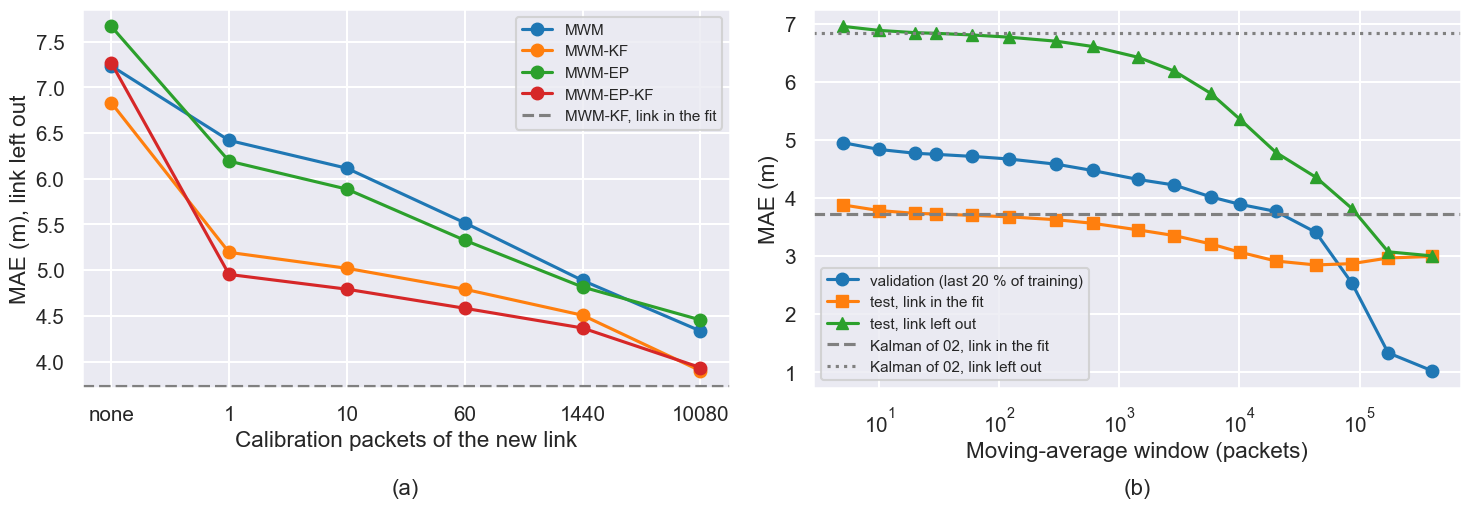

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) left-out link: MAE against the calibration window
for m in MODELS:
    ax1.plot(range(len(CAL)), [mae_by_link(res, 'lolo', N, [m]).loc['mean over links', m] for N in CAL], marker='o', label=m)
ax1.axhline(mae_by_link(res, 'fit', 0, ['MWM-KF']).loc['mean over links', 'MWM-KF'], color='gray', linestyle='--', label='MWM-KF, link in the fit')
ax1.set_xticks(range(len(CAL)))
ax1.set_xticklabels(['none'] + [str(N) for N in CAL[1:]])
ax1.set_xlabel('Calibration packets of the new link')
ax1.set_ylabel('MAE (m), link left out')
ax1.legend(fontsize=11)
ax1.text(0.5, -0.28, '(a)', transform=ax1.transAxes, ha='center', fontsize=16)

# (b) moving average: MAE against the window
ax2.plot(windows, [validation['mean'][w] for w in windows], marker='o', label='validation (last 20 % of training)')
ax2.plot(windows, [sweep[w]['link in the fit'] for w in windows], marker='s', label='test, link in the fit')
ax2.plot(windows, [sweep[w]['link left out'] for w in windows], marker='^', label='test, link left out')
ax2.axhline(pooled(res, 'fit', 'MWM-KF')[0], color='gray', linestyle='--', label='Kalman of 02, link in the fit')
ax2.axhline(pooled(res, 'lolo', 'MWM-KF')[0], color='gray', linestyle=':', label='Kalman of 02, link left out')
ax2.set_xscale('log')
ax2.set_xlabel('Moving-average window (packets)')
ax2.set_ylabel('MAE (m)')
ax2.legend(fontsize=11)
ax2.text(0.5, -0.28, '(b)', transform=ax2.transAxes, ha='center', fontsize=16)

plt.tight_layout()
plt.savefig('Figures/robustness_calibration_smoothing.png', dpi=300, bbox_inches='tight')
plt.savefig('Figures/robustness_calibration_smoothing.pdf', bbox_inches='tight')
plt.show()